In [2]:
import os
import cv2
import json
import keras
import random
import numpy as np
from glob import glob
from natsort import natsorted
from keras.models import Model
from keras import backend as K
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage
from KerasModels import Easter2, Easter2b
from Modules import PatchedPerigLayoutDetection, PatchedLineDetection, KerasInference
from Utils import rotate_from_hough, get_line_images_from_line_data
print(tf.__version__)
print(keras.__version__)




2.15.0
2.15.0


In [7]:
def show_image(image: np.array, cmap: str = "") -> None:
    plt.figure(figsize=(24, 13))
    #plt.axis("off")
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)


def get_charset(characters: str):
    """
    To be used when reading a charset from a config file
    """
    characters = [c for c in characters]
    characters.append("[BLK]")
    characters.insert(0, "[UNK]")

    return characters

def get_random_color():
    rand_r = random.randint(40, 255)
    rand_g = random.randint(40, 200)
    rand_b = random.randint(40, 220)
    color = (rand_r, rand_g, rand_b)

    return color

def binarize_line(image: np.array, adaptive: bool = True, blur: bool = False):
    d_kernel = np.ones((2, 2), np.uint8) 

    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    
    if blur:
        image = cv2.GaussianBlur(image, (3, 3), 0)
    if adaptive:
        image = cv2.adaptiveThreshold(image, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 51, 14)
    
    else:
        _, image = cv2.threshold(image, 110, 255, cv2.THRESH_BINARY|cv2.THRESH_OTSU)
    image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)

    return image

In [8]:
#inference_model = Model(model.get_layer("images").input, model.get_layer("Final").output)
#keras_model =  keras.saving.load_model("Models/OCRModels/GlomanThang/2024_1_22_15_34/GlomanThang_easter2b.keras", safe_mode=False, custom_objects={"K": K})

layout_config = "Models\LayoutModels\LA_v2_2024-1-22_6-36\model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

line_model_config = "Models/LineModels/line_model_config.json"
line_inference = PatchedLineDetection(config_file=line_model_config, binarize_output=False, mode="cuda")

Assuming model path: Models\LineModels
Line Inference -> Init(): True


Test images: 652


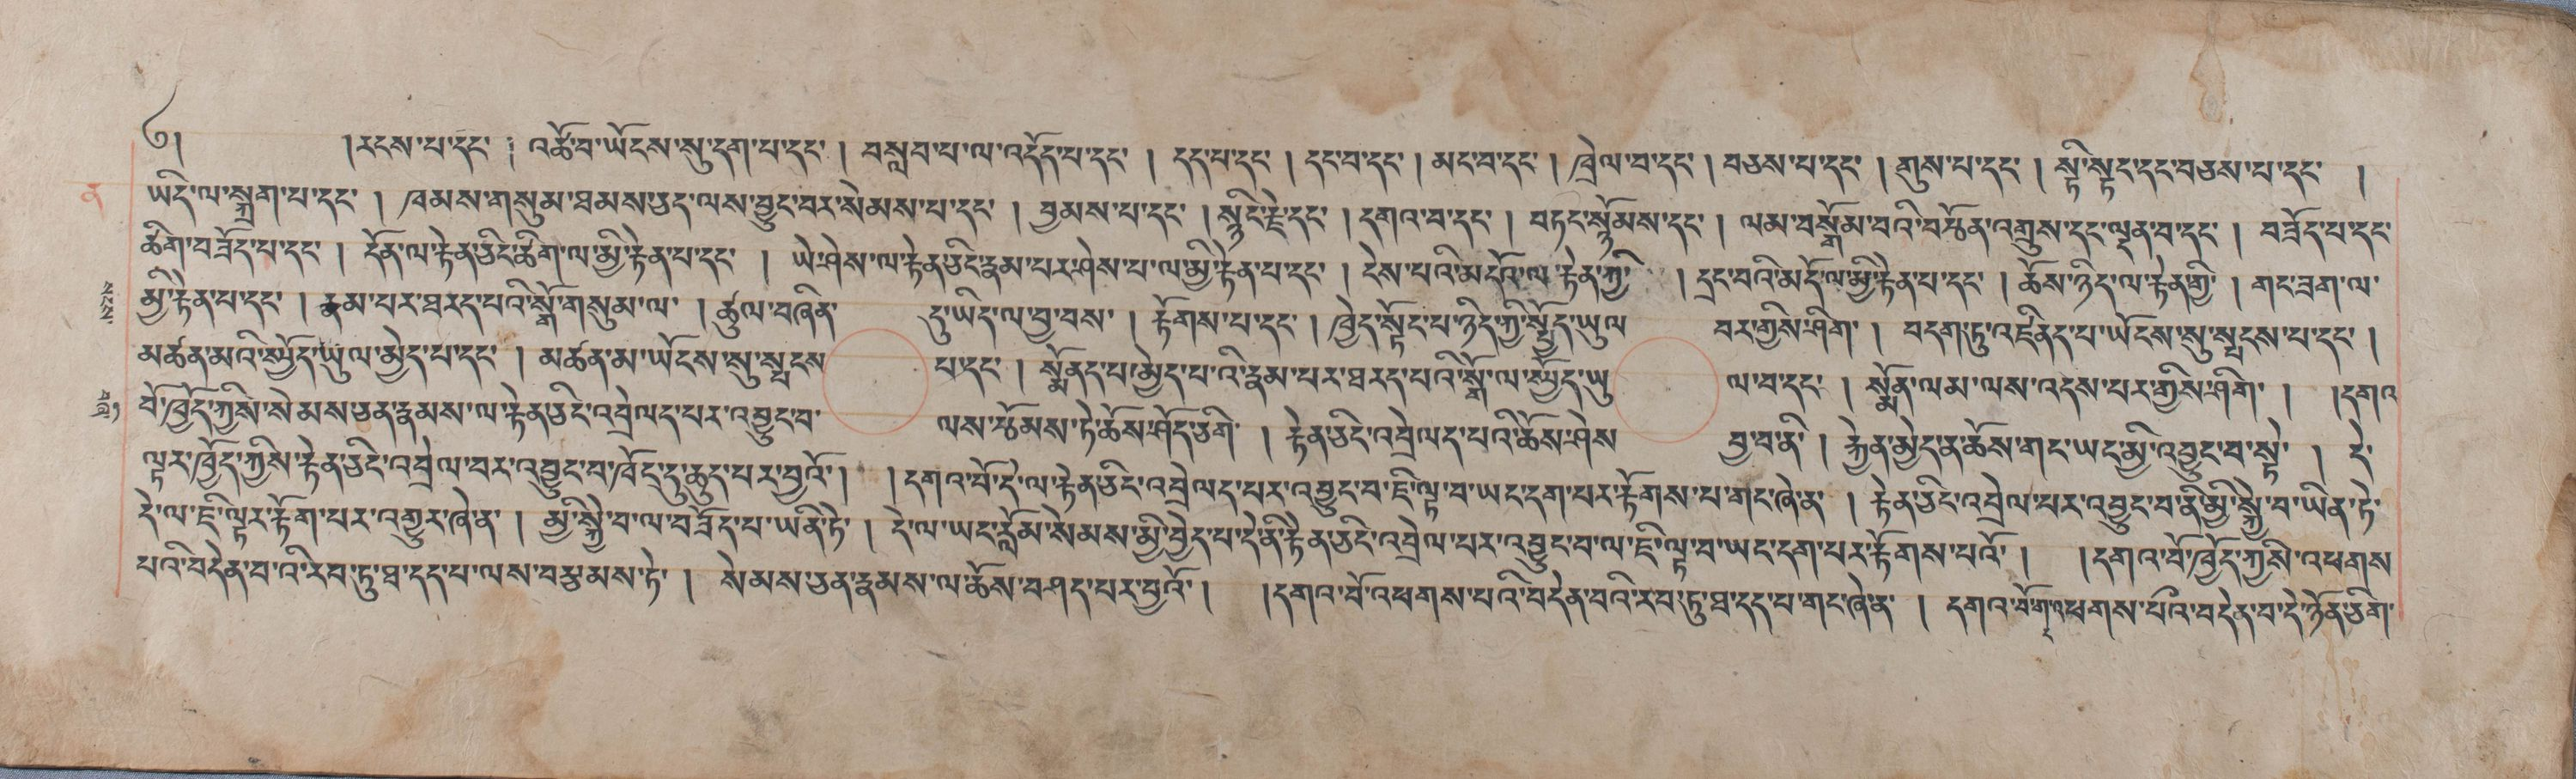

In [6]:
data_root = "D:\Datasets\Tibetan\Glomanthang\Volumes"
test_set = "W2KG229028-v12"
images = natsorted(glob(f"{os.path.join(data_root, test_set)}/*.jpg"))

print(f"Test images: {len(images)}")

img_idx = 5
ShowImage(images[img_idx])

Test images: 1126


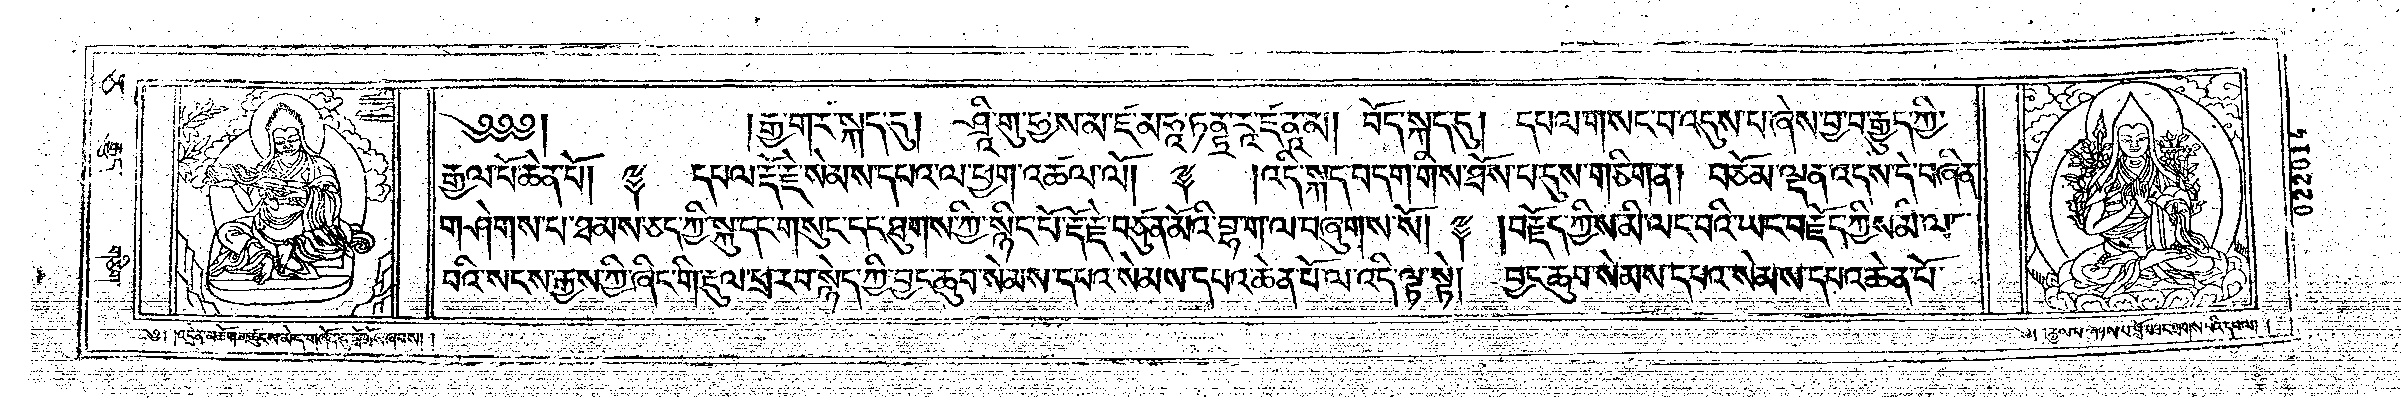

In [13]:
data_root = "Data"
#test_set = "W23703/I1380" # Derge Tenjur

#image_path = "D:/Github/OCR-Inference/Data/W21521-v8"
#test_set = "W22106/I1KG11830" # Buston gsung 'bum
test_set = "W22272-v5"# Tsong-kha-pa
image_path = os.path.join(data_root, test_set)
images = natsorted(glob(f"{image_path}/*.jpg"))

print(f"Test images: {len(images)}")

img_idx = 5
ShowImage(images[img_idx])

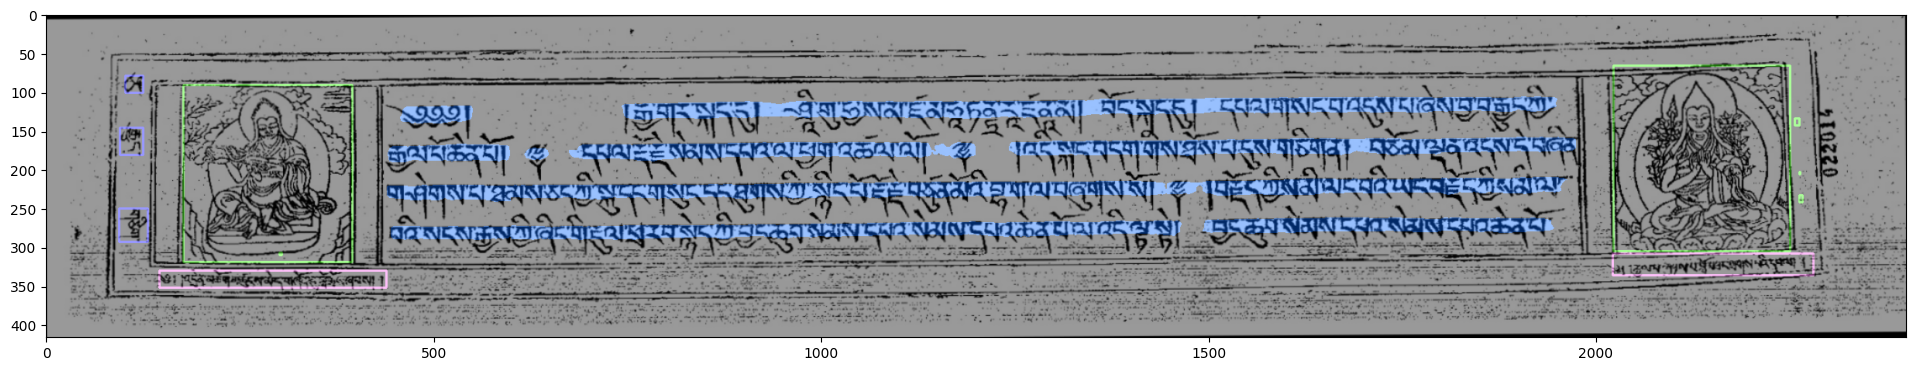

In [14]:
# layout_inference
try:
  image_name = os.path.basename(images[img_idx]).split(".")[0]
  _img = cv2.imread(images[img_idx])

except FileExistsError as e:
    print.error(f"Cant read file at provided location: {images[img_idx]}, {e}")

# layout_inference
layout_data, preview_img = layout_inference.predict(_img)
show_image(preview_img)

line_treshold: 24.0


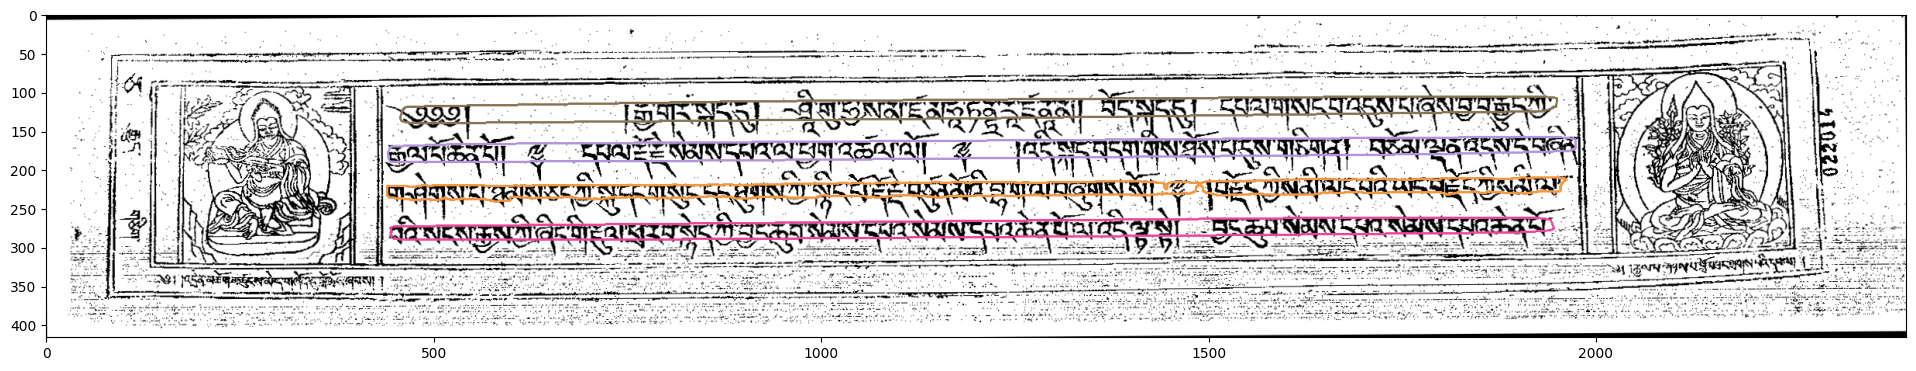

In [22]:
sorted_layout_data = layout_inference.sort_lines(layout_data)

p_img, angle = rotate_from_hough(_img)
prev_img = p_img.copy()
color = get_random_color()

for line_data in layout_data.lines:
    color = get_random_color()
    cv2.drawContours(prev_img,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(prev_img) 

In [9]:
layout_line_images = get_line_images_from_line_data(p_img, sorted_layout_data.lines, dilate_kernel=24, dilate_iterations=5)
binarized_lines = [binarize_line(x) for x in layout_line_images]

#### preview lines

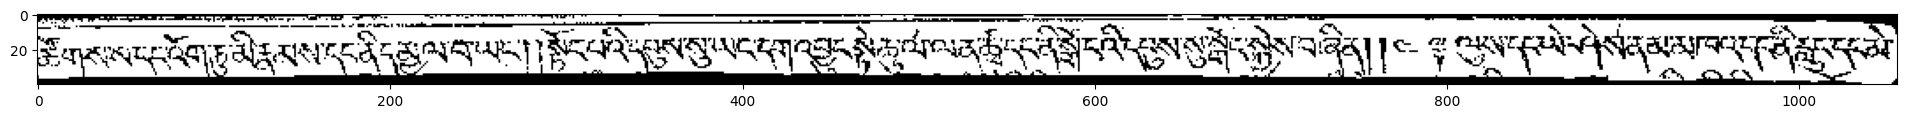

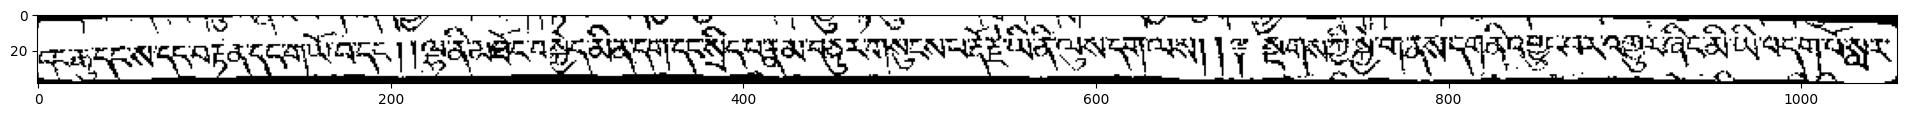

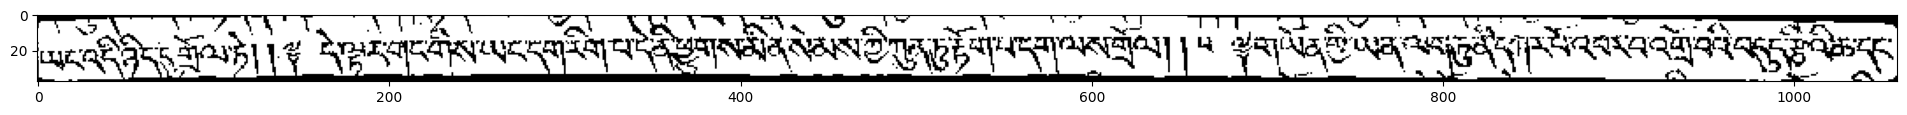

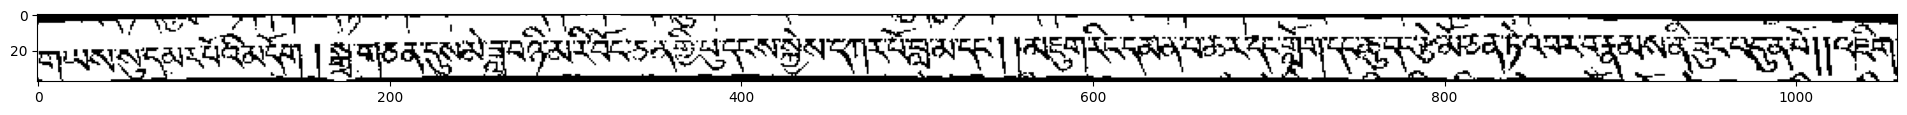

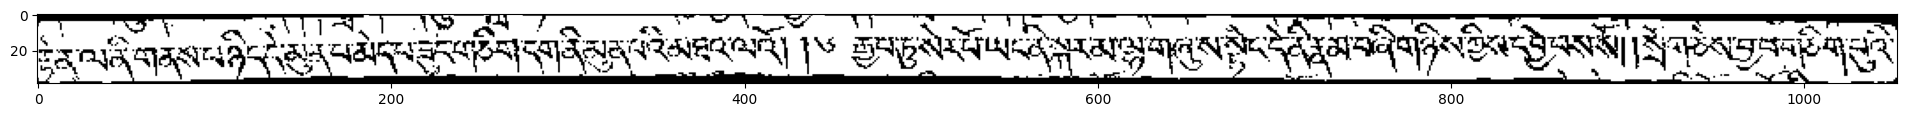

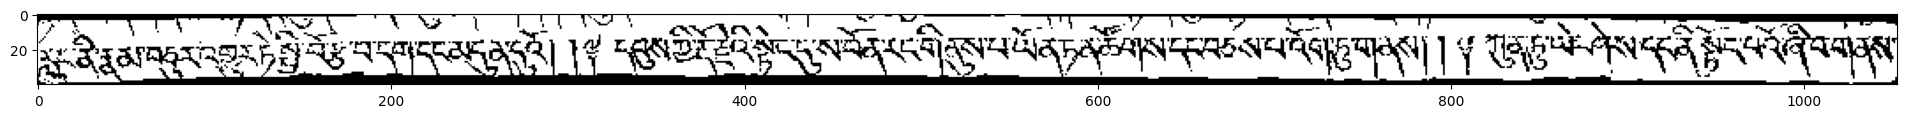

In [10]:
for idx, img in enumerate(binarized_lines):
    show_image(binarized_lines[idx])

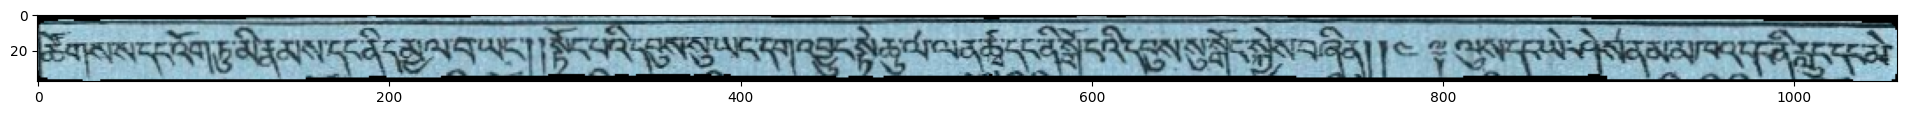

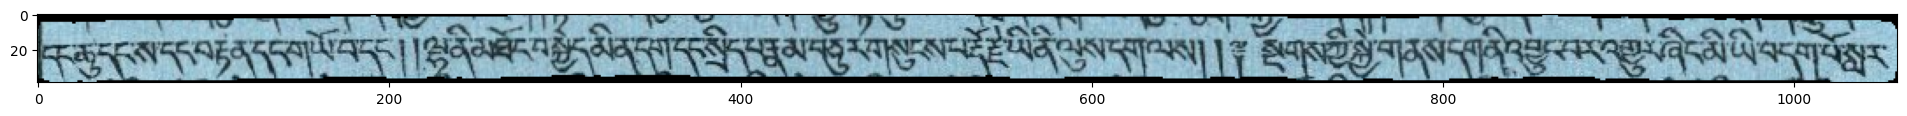

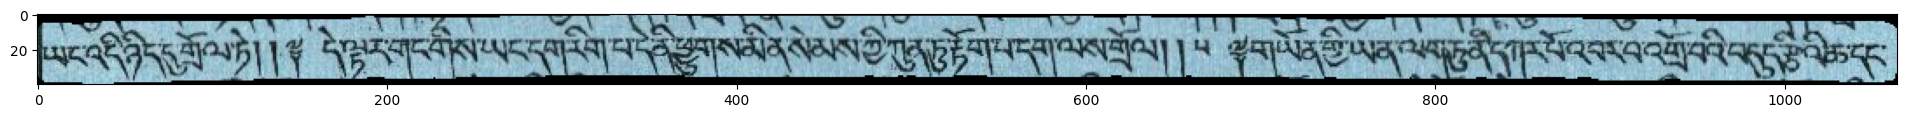

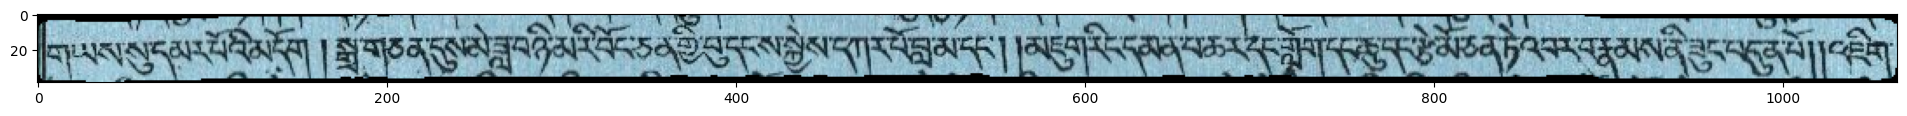

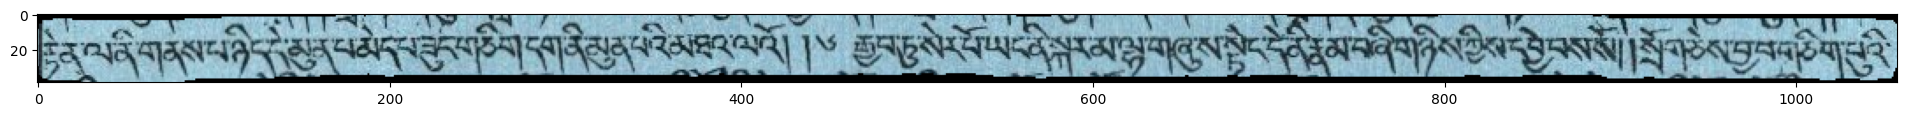

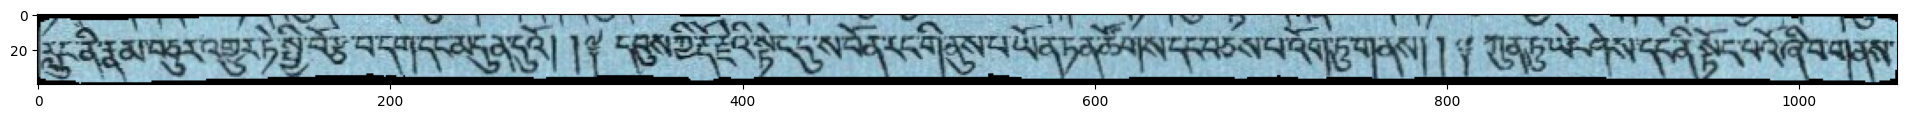

In [11]:
back_sized_image, rotated_image, line_images, sorted_contours, bbox, peaks = line_inference.predict(_img, 0, line_kernel=18)


for idx, img in enumerate(line_images):
    show_image(line_images[idx])

In [12]:
binarized_line_detection_lines = [binarize_line(x) for x in line_images]

#### Keras Inference

In [13]:
from Utils import prepare_tf_ocr_image, prepare_ocr_image, pad_image2

In [ ]:
#Models\OCRModels\GlomanThang\GlomanThang_bw_models\2024_1_24_12_9\Glomanthang_easter2b.hdf5

In [16]:
models_path = "Models/OCRModels"
dataset = "DergeTenjur"
chkpt_path = "2024_1_25_6_48"
keras_model_config = f"{models_path}/{dataset}/{chkpt_path}/model_config.json"
keras_inf = KerasInference(keras_model_config)

Loading Easter2b
Y_pred: KerasTensor(type_spec=TensorSpec(shape=(None, 500, 77), dtype=tf.float32, name=None), name='Final/Softmax:0', description="created by layer 'Final'")


In [17]:
def prepare_ocr_image2(
line_image: np.array, target_width: int = 2000, target_height: int = 80
):
    if len(line_image.shape) > 2:
        line_image = cv2.cvtColor(line_image, cv2.COLOR_BGR2GRAY)

    image = pad_image2(
        line_image,
        target_width=target_width,
        target_height=target_height,
        padding="black",
    )

    image = image.reshape((target_height, target_width, 1))
    #image = (image / 127.5) - 1.0
    image = image / 255.0
    image = image.astype(np.float32)
    return image

In [18]:
tf_line_batch = [
prepare_tf_ocr_image(
    x, target_width=keras_inf._input_width, target_height=keras_inf._input_height
)
for x in binarized_line_detection_lines
]

t_line_batch = np.array(tf_line_batch, dtype=np.float32)

t_line_batch = t_line_batch[:, :, :, 0]
print(t_line_batch.shape)
ocr_prediction = keras_inf.run(t_line_batch)

for line in ocr_prediction:
    print(line)

(6, 2000, 80)
(6, 2000, 80)
རིགས་པ་དང་འོག་ཏུ་མི་རྣམས་དང་ནི་དམྱལ་བ་ཡང་།སྟོང་པའི་དབུས་སུ་ཡང་དག་འབྱུང་སྟེ་ཆུ་ལ་ལན་ཚྭ་ད་ང་ནི་སྲེདའི་དབུས་སུ་སྲེང་སྐྱེས་བཞིན།ལུས་དང་ཡེ་ཤེས་ནམ་མཁའ་ནི་རླུང་དང་མེ་
དང་ཆུ་དང་ས་དང་བརྟན་དང་གཡོ་བ་དང་།ལྷ་ནི་མཐོང་བསྐྱེད་མིན་དག་དང་སྲིད་པ་རྣམ་བཅུར་གསུངས་པ་རྡོ་རྗེ་ཡི་ནི་ལུས་ངག་ལས།སྔགས་ཀྱི་སྐྱེ་གནས་དག་ནི་འབྱུང་བར་འགྱུར་ཞིང་མེ་ཡི་བདག་པོ་སླར་
ཡང་འདི་ཉིད་དུ་གྲོལ་ཏེ།དེ་ལྟར་གང་གིས་ཡང་དག་རིག་པ་དེ་ནི་ཕྱུགས་མིན་སེམས་ཀྱི་ཀུན་ཏུ་རྟོག་པ་དག་ལས་གྲོལ།པ་ལྟ་གཡོན་གྱི་ཡན་ལག་ཏུ་ནི་དཀར་པོ་འབར་བ་འགྲོ་བའི་བདུད་རྩིའི་ཆ་དང་
གཡས་སུ་དམར་པོའི་མདོག་།སྒྲ་གཅན་དུས་མེ་ཟླ་བ་ཉི་མ་རི་བོང་ཅན་གྱི་བུ་དང་ས་སྐྱེས་དཀར་པོ་བླ་མ་དང་།མཇུག་རིང་དམན་པ་ཆར་དང་གློག་དང་ཆུ་བང་རྩེ་མོ་ཅན་ཏེ་འབར་བ་རྣམས་ནི་ཟུང་བདུན་པེ།འཇིག་
ཏེན་ལ་ནི་གནས་པ་ཉིད་དེ་མུར་པ་མེད་པ་ཟུང་གཅིག་དག་ནི་མུན་པའི་མཐའ་ལའོ།རྒྱབ་ཏུ་སེར་པོ་ཡང་ནི་སྐར་མ་ལྷ་གཞུ་མ་སྟེང་དེ་ནི་རྣམ་བཞི་གཉིས་ཀྱིས་དབྱེ་བས་སོ།སྲེ་བ་ཅེས་བྱ་བ་གཅིག་པུའི་
དུང་ནི་རྣམ་བཅུར་འགྱུར་ཏེ་སྤྱི་བོ་རྩེ་བ་དག་དང་མདུན་དུའོ། དབུས་ཀྱི་རྡོ་རྗེའི་སྟེང་དུ་ས་བོན་རང་གི་ནུས་པ་ཡོན་ཏན་ཚོགས་དང་བཅས་པ་འོག་ཏུ་གནས།ཀུན་ཏུ་ཡེ

In [19]:
tf_line_batch = [
prepare_tf_ocr_image(
    x, target_width=keras_inf._input_width, target_height=keras_inf._input_height
)
for x in binarized_lines
]

tf_line_batch = np.array(tf_line_batch, dtype=np.float32)
tf_line_batch = tf_line_batch[:, :, :, 0]
print(tf_line_batch.shape)
ocr_prediction = keras_inf.run(tf_line_batch)

for line in ocr_prediction:
    print(line)

(6, 2000, 80)
(6, 2000, 80)
ཏཛོགས་པ་དང་འོག་ཏུ་མི་རྣམས་དང་ནི་དམྱལ་བ་ཡང་།སྟོང་པའི་དབུས་སུ་ཡང་དག་འབྱུང་སྟེ་ཆུ་ལ་ལན་ཚ་དང་ནི་སྒེ་ངའི་དབུས་སུ་སྐེད་སྐྱེས་བཞིན།ལུས་དང་ཡེ་ཤེས་ནམ་མཁའ་བ་ཤི་རླུང་དང་མེ་
དང་ཆུ་དང་ས་དང་བརྟན་དང་གཡོ་བ་དང་།ལྷ་ནི་མཐོང་བསྐྱེད་མིན་དག་དང་སྲིད་པ་རྣམ་བཅུར་གསུངས་པ་རྡོ་རྗེ་ཡི་ནི་ལུས་ངག་ལས།སྔགས་ཀྱི་སྐྱེ་གནས་དག་ནི་འབྱུང་བར་འགྱུར་ཞིང་མི་ཡི་བདག་བ་སླར་
མཛད་དེ་ཉིད་དུ་གྲོལ་ཏེ།དེ་ལྟར་གང་གིས་ཡང་དག་རིག་པ་དེ་ནི་ཕྱུགས་མིན་སེམས་ཀྱི་ཀུན་ཏུ་རྟོག་པ་དག་ལས་གྲོལ།རས་གཡོན་གྱི་ཡན་ལག་ཏུ་ནི་དཀར་པོ་འབར་བ་འགྲོ་བའི་བདུད་རྩི་འི་ཆ་དང་
གཡས་སུ་དམར་བོའི་མདོག་།སྒྲ་གཅན་དུས་མེ་ཟླ་བ་ཉི་མ་རི་བོང་ཅན་གྱི་བུ་དང་ས་སྐྱེས་དཀར་པོ་བླ་མ་དང་།མཇུག་རིང་དམན་པ་ཆར་དང་གླེག་དང་ཆུ་བང་རྩེ་མོ་ཅན་ཏེ་འབར་བ་རྣམས་ནི་ཟུང་བདུན་པེ།འཇིག་
རྟེན་ལ་ནི་གནས་པ་ཉིད་དེ་མུར་པ་མེད་པ་ཟུང་གཅིག་དག་ནི་མུན་པའི་མཐའ་ལའོ།རྒྱབ་ཏུ་སེར་པོ་ཡང་ནི་སྐར་མ་ལྷ་གཞུས་སྟེང་དེ་ནི་རྣམ་བཞི་གཉིས་ཀྱིས་དབྱེ་བས་སོ།སྲེག་ཅེས་བྱ་བ་གཅིག་པུའི་
རླུང་ནི་རྣམ་བཅུར་འགྱུར་ཏེ་མྱི་བརྩེ་བ་དག་དང་མདུན་དུའོ།དབུས་ཀྱི་རྡོ་རྗེའི་སྟེང་དུ་ས་བོན་རང་གི་ནུས་པ་ཡོན་ཏན་ཚོགས་དང་བཅས་པ་འོག་ཏུ་གནས།ཀུན་ཏུ་ཡེ་ཤེས

In [50]:
line_batch = [
prepare_ocr_image2(
    x, target_width=keras_inf._input_width, target_height=keras_inf._input_height
)
for x in binarized_line_detection_lines
]

line_batch = [np.transpose(x, axes=[1, 0, 2]) for x in line_batch]
np_line_batch = np.array(line_batch, dtype=np.float32)
np_line_batch = np_line_batch[:, :, :, 0]
print(np_line_batch.shape)

(6, 2000, 80)


In [51]:
ocr_prediction = keras_inf.run(np_line_batch)

for line in ocr_prediction:
    print(line)


(6, 2000, 80)
པར་དངང་ཏུ་མི་རྣམས་དང་ནི་ང་རྒྱལ་བ་ཡང་།སྟོང་པའི་དབུས་སུ་ཡང་དག་འབྱུང་སྟེ་ཐུལ་ལན་ཚ་དང་ནི་སྲེ་དའི་དབྱས་སུ་སྐྱེར་སྐྱེས་ཞིན།ལས་དང་ཡེ་ཤེས་ནམ་མཁའཧན་
ཆུ་དང་ས་དང་བརྟན་དང་གྱོའ་དང་།ལྷ་ནི་མཐེང་བསྐྱེད་མིན་དག་དང་སྲིད་པ་རྣམ་བཅུར་གསུངས་པ་རྡོ་རྗེ་ཡི་ནི་ལས་དག་ལས།སྔགས་ཀྱི་སྐྱེ་གནས་དག་ནི་འབྱུང་བར་འགྱུར་ཞིང་མི་ཡེ་བདགབ་སྨྲ།
ཡང་འདི་ཉིད་དུ་གྲོལ་ཏེ།དེ་ལྟར་གང་གིས་ཡང་དག་རིག་པ་དེ་ནི་ཕྱུགས་མིན་སེམས་ཀྱི་ཀུན་ཏུ་རྟོག་པ་དག་ལས་གྲེལ།ཕ་རྟ་གྱོན་གྱི་ཡན་ལག་ཏུ་ནི་དཀར་པོ་འབར་བ་འགྲེ་བའི་བདུད་རྟེའི་ཆ་དང་།
གྱས་སུ་དམར་པོའི་མདོག་།སྒྲ་གཅན་དུས་མེ་ཟླ་བ་ཉི་མ་རི་བོང་ཅན་གྱི་བུ་དང་ས་སྐྱེས་དཀར་པོ་བླ་མ་དང་།མཇུག་རིང་དམན་པ་ཆར་དང་གློག་དང་ཆུ་བ་རྩེ་མེ་ཅན་ཏེ་འབར་བ་རྣམས་ནི་ཟུང་བདུན་པོ།འཇིག་
རྟན་ལ་ནི་གནས་པ་ཉིད་དེ་མྱུར་པ་མེད་པ་ཟུང་གཅིང་།ངག་ནི་མྱུན་པའི་མཐའ་ལའོ།རྒྱབ་ཏུ་སེར་པོ་ཡང་ནི་སྐར་མ་ལྷ་གཞུས་སྟེང་དེ་ནི་རྣམ་པ་ཞི་གཉིས་ཀྱིས་དབྱེ་བས་སོ།སྲེག་ཅེས་བྱ་འཧའཅིག་པའི་
སླུང་ནི་རྣམ་བཅུར་འགྱུར་ཏེ་སྐྱི་བོ་རྩེ་བ་དག་དང་མདུན་དུའི།དབུས་ཀྱི་རྡོ་རྗེའི་སྟེང་དུ་ས་བོན་རང་གི་ནུས་པ་ཡོན་ཏན་ཚོགས་དང་བཅས་པ་འོང་ཏུ་གནས།ཀུན་ཏུ་ཡེ་ཤེས་དང་ནི་སྟེང་པའི་ཞི་བ་གནས་


In [52]:
line_batch = [
prepare_ocr_image2(
    x, target_width=keras_inf._input_width, target_height=keras_inf._input_height
)
for x in binarized_lines
]

line_batch = [np.transpose(x, axes=[1, 0, 2]) for x in line_batch]
np_line_batch = np.array(line_batch, dtype=np.float32)
np_line_batch = np_line_batch[:, :, :, 0]
print(np_line_batch.shape)
ocr_prediction = keras_inf.run(np_line_batch)

for line in ocr_prediction:
    print(line)


(6, 2000, 80)
(6, 2000, 80)
རྟརགཔགཆིག་ཏུ་མི་རྣམས་དང་ནི་དརྒྱལ་བ་ཡང་།སྟོང་པའི་དབྱུས་སུ་ཡང་དག་འབྱུང་སྟེ་ཆུལ་ལན་ཚུ་དང་ནི་སྒེ་ངའི་དབྱུས་སུ་སྒེན་སྐྱེས་བཞིན།ལྟ་ལུས་དང་ཡེ་ཤེས་ནམ་མཁའ་དང་ནི་རླུང་དང་མེ་
དན་བརྟེན་དང་རྒམ་འ་དང་།ལྷ་ནི་མཐོང་འསྐྱེད་མིན་དག་དང་སྲིད་པ་རྣམ་བཅུར་གསུངས་པ་རྡོ་རྗེ་ཡི་ནི་ལུས་ངག་ལས།སྔགས་ཀྱི་སྐྱེ་གནས་ངག་ནི་འབྱུང་བར་འགྱུར་ཞིང་མི་ཡི་བདག་འོ་སླར་
ཨུ་རྒྱུ་ས་རྟེ།དེ་ལྟར་གང་གིས་ཡང་དག་རེག་པ་དེ་ནི་ཕྱུགས་མིན་སེམས་ཀྱི་ཀུན་ཏུ་རྟོག་པ་དག་ལས་གྲོལ།ལྟ་འགྱོན་གྱི་ཡན་ལག་ཏུ་ནི་དཀར་པོ་འབར་བ་འགྲེ་བའི་བདུད་རྩི་འཆ་དང་
རྣ་ཧམརྨདག།སྒྲོགཏན་དུས་མེ་ཟླ་བ་ཉི་མ་རི་བོང་ཅན་གྱི་བུ་དང་ས་སྐྱེས་དཀར་པོ་བླ་མ་དང་།མཇུག་རིང་དམན་པ་ཆར་དང་གློག་དང་ཆུ་བང་རྩེ་མོ་ཅན་ཏེ་འབར་བ་རྣམས་ནི་ཟུང་བདུན་པ།འཇིག་
ག་རྣམ་པ་ཉིདའེ་མྱེན་པ་མེད་པ་ཟུང་གཅིག་དག་ནི་མྱན་པའི་མཐའ་ལའོ།རྒྱལ་ཏུ་སེར་པོ་ཡང་ནི་སྐར་མ་ལྷ་གཞུས་སྟིང་དེ་ནི་རྣམ་པ་ཞི་གཉིས་ཀྱིས་དབྱེ་བས་སོ།སྲེག་ཅེས་བྱ་བ་གཅིག་པུའི་
མ་ཨུར་འགྱུར་ཏེ་མྱི་བརྩེ་བ་དག་དང་མདུན་དུའོ།ལྟ་དབུས་ཀྱི་རྡོ་རྗེའི་སྟེང་དུ་ས་བོན་རང་གི་ནུས་པ་ཡོན་ཏན་ཚོགས་དང་བཅས་པ་འོག་ཏུ་གནས།ཀུན་ཏུ་ཡེ་ཤེས་དང་ནི་སྟེང་པའི་ཞི་བ་གནས་


#### ONNX-OCR

In [54]:
import cv2
from Config import COLOR_DICT
from Utils import rotate_from_hough, binarize_line
from DataClasses import LineData

from IPython.display import Image as ShowImage

In [58]:
layout_line_images = get_line_images_from_line_data(p_img, sorted_layout_data.lines)

for idx, img in enumerate(layout_line_images):
    show_image(layout_line_images[idx])

ONNX Inference

In [21]:
from Utils import prepare_ocr_image, binarize_line
from fast_ctc_decode import viterbi_search, beam_search
import onnxruntime as ort

In [66]:
#ocr_model_config = "Models/OCRModels/LithangKanjur/2023_12_6_7_13/model_config.json"
#ocr_model_config = "Models/OCRModels/LhasaKanjurEaster/ocr_model_config.json"
#ocr_model_config = "Models/OCRModels/DergeTenjur/ocr_model_config.json"
ocr_model_config = "Models/OCRModels/LhasaKanjur/ocr_model_config.json"
_file = open(ocr_model_config, encoding="utf-8")
json_content = json.loads(_file.read())
onnx_model_file = json_content["gpu-model"]
input_width = json_content["input_width"]
input_height = json_content["input_height"]
input_layer = json_content["input_layer"]
output_layer = json_content["output_layer"]
squeeze_channel_dim = (True if json_content["squeeze_channel_dim"] == "yes" else False)
swap_hw = True if json_content["swap_hw"] == "yes" else False
characters = json_content["charset"]

print(onnx_model_file)
print(f"{len(characters)}: {characters}")

sess = ort.InferenceSession(onnx_model_file)

Models/OCRModels/LhasaKanjur/LhasaKanjur_gpu.onnx
75: ß !#%'()+-./0123456789:=?@ADHIMNRSTUWXY[\]_abcdefghijklmnoprstuwyz|~&äüö<>;


In [34]:
for input in sess.get_inputs():
    print(input.name)
    print(input.shape)

input
['batch_size', 1, 80, 2000]


In [46]:
from Utils import pad_image2

def prepare_tf_ocr_image(image: np.array, target_height: int = 80, target_width: int = 2000):
    tf_img = tf.image.resize_with_pad(image, target_height, target_width)
    tf_img = tf_img / 255.0
    
    tf_img = tf.transpose(tf_img, perm=[1, 0, 2])
    tf_img = tf.squeeze(tf_img)

    return tf_img.numpy()

def prepare_ocr_image_v2(
    line_image: np.array, target_width: int = 2000, target_height: int = 80
):
    if len(line_image.shape) > 2:
        line_image = cv2.cvtColor(line_image, cv2.COLOR_BGR2GRAY)

    image = pad_image2(
        line_image,
        target_width=target_width,
        target_height=target_height,
        padding="black",
    )

    image = image.reshape((1, target_height, target_width))
    #image = np.expand_dims(image, axis=-1)
    #image = image / 255
    image = (image / 127.5) - 1.0
    image = image.astype(np.float32)
    return image

In [266]:
img_batch = [binarize_line(x, adaptive=False) for x in line_images]

In [60]:
line_img_batch = [
            prepare_ocr_image_v2(
                x, target_width=input_width, target_height=input_height
            )
            for x in line_images
        ]


layout_img_batch = [prepare_ocr_image_v2(x, target_width=input_width, target_height=input_height) for x in layout_line_images]

In [61]:
line_img_batch = np.array(line_img_batch, np.float32)
layout_img_batch = np.array(layout_img_batch, np.float32)

In [62]:
print(line_img_batch.shape)
print(layout_img_batch.shape)

(7, 1, 80, 2000)
(7, 1, 80, 2000)


In [63]:
line_ort_batch = ort.OrtValue.ortvalue_from_numpy(line_img_batch)
layout_ort_batch = ort.OrtValue.ortvalue_from_numpy(layout_img_batch)

In [47]:
if squeeze_channel_dim:
    img_batch = np.squeeze(img_batch, axis=1)
if swap_hw:
    img_batch = np.transpose(img_batch, axes=[0, 2, 1])

(7, 1, 80, 2000)


In [70]:
ocr_results = sess.run_with_ort_values([output_layer], {input_layer: line_ort_batch})
prediction = ocr_results[0].numpy()
print(prediction.shape)

predicted_text = []

for idx in range(prediction.shape[0]):
    pred_line = prediction[idx, :, :]
    text, _ = viterbi_search(pred_line, characters)
    #text, _ = beam_search(pred_line, characters, beam_size=5, beam_cut_threshold=0.01)

    if len(text) > 0:
        #text = text.replace("§", " ")
        predicted_text.append(text)
    else:
        predicted_text.append("")

print(predicted_text)

(499, 7, 75)
['nk', 'slbnay', 'spayai', 'oai ', 'a zr', ' zdln', ' ha', '|kbi a', ' k m', ' hny', '|yrys', 'ot i ', '  ', 'ed p', 'dnu a', 'n nga', ' r', 's b r', 'n ', 'ok ', 'yadt ', 'iaecs', ' saeim', ' g/i', 's  gi', 's g', 'ot n', 'h n', ' hk ', ' oy ', 's batp', 's bndu', 'k gua', 'y e ', 'ep g ', 'oads', ' ay', ' ', 'b g a', 'oyg ', 'onern', ' i ag', '  a ', 'n bg ', 'i nang ', " ng'", ' t ', "r ' ", 'da isd', 'zn pd', 'uorar', ' n t e', '  sn n', "'sagrn", ' nagn', ' y a ', 'pabsa ', 'pgmasm', 'hym ma', 'ri a', "r 'r ", 'u g ', ' nysy', 'ltnday', 'ladi', 'si ', 'hss', 'osk', ' syn', '  i', '/ ', 'lg rlr ', ' dn', 'aza', 'uao', ' /', " ' m ", 'sd ', 'msepm/', 'mp ', 'ysh ', 'a srp', ' up', ' ca', 'r lcd', "'rhr", 'aor', ' a  ', ' n d g', 'dgcdse', 'd c me', 'u h  ', 'isepi ', '  as', ' abal', 'sla no', 'ln o', 'etg  n', 'adb g', 'ayp ', 'sna ', 'm nad', 'm gs a', 'r s a', 'bg ng', 'ym g', 'ua i ', ' ', 'sng ', 'srstagd', 'he', 'hs ', ' u ', ' l', 'g dc ct', 'bec it', 'ehsia', 'e

### Keras Inference Garbage

In [ ]:
model = Easter2b(classes=len(model_chars))
model.load_weights("Models/OCRModels/GlomanThang/2024_1_22_22_20/GlomanThang/Dataset_January2024_merged_easter2b.hdf5")

In [36]:
def predict_ocr(tf_img):
    print(tf_img.shape)
    prediction = inference_model.predict(tf_img)
    out = K.get_value(K.ctc_decode(prediction,
                                        input_length=np.ones(prediction.shape[0]) * prediction.shape[1],
                                        greedy=True)[0][0])[0]

    return out


def prepare_ocr_image(image: np.array, target_height: int = 80, target_width: int = 2000):
    tf_img = tf.image.rgb_to_grayscale(image)
    tf_img = tf.image.resize_with_pad(tf_img, target_height, target_width)
    img = tf.cast(img, tf.float32) / 255.0
    
    tf_img = tf.transpose(tf_img, perm=[1, 0, 2])
    tf_img = tf.squeeze(tf_img)

    return tf_img

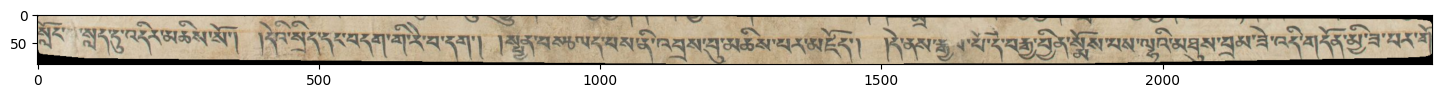

In [52]:
show_image(line_images[-1])

In [28]:
line_img = line_images[-1]
t_img = prepare_ocr_image(line_img)
t_img = tf.expand_dims(t_img, axis=-1)
print(t_img.shape)

out = predict_ocr(t_img)
print(out)

(2000, 80, 1)
(2000, 80, 1)


InvalidArgumentError: Graph execution error:

Detected at node model_1/conv1d/Conv1D defined at (most recent call last):
  File "C:\Users\Eric\AppData\Local\Programs\Python\Python310\lib\runpy.py", line 196, in _run_module_as_main

  File "C:\Users\Eric\AppData\Local\Programs\Python\Python310\lib\runpy.py", line 86, in _run_code

  File "d:\Github\OCR-Inference\venv\lib\site-packages\ipykernel_launcher.py", line 17, in <module>

  File "d:\Github\OCR-Inference\venv\lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance

  File "d:\Github\OCR-Inference\venv\lib\site-packages\ipykernel\kernelapp.py", line 739, in start

  File "d:\Github\OCR-Inference\venv\lib\site-packages\tornado\platform\asyncio.py", line 205, in start

  File "C:\Users\Eric\AppData\Local\Programs\Python\Python310\lib\asyncio\base_events.py", line 603, in run_forever

  File "C:\Users\Eric\AppData\Local\Programs\Python\Python310\lib\asyncio\base_events.py", line 1909, in _run_once

  File "C

In [74]:
def read_tf_image_v1(img_path: str):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=1)
    img = tf.image.resize_with_pad(img, 80, 2000)

    return img.numpy(), img

4147


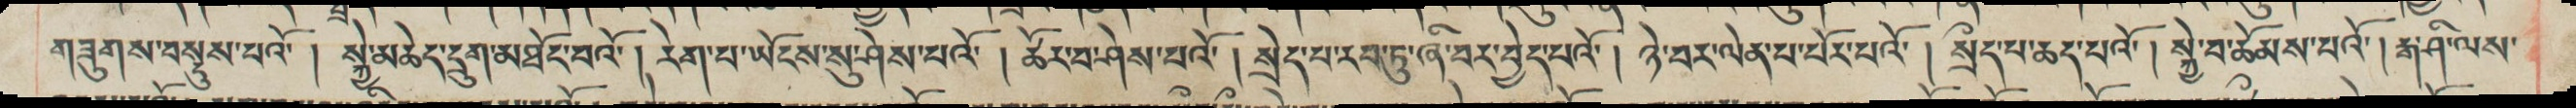

In [45]:
ds_lines = natsorted(glob(f"D:\Datasets\Tibetan\Glomanthang\Annotations_v2\Glomanthang-Annotations\Dataset_January2024_merged\lines\*.jpg"))
print(len(ds_lines))
test_img = ds_lines[123]
ShowImage(test_img)

In [83]:
from Utils import resize_to_width, pad_image2

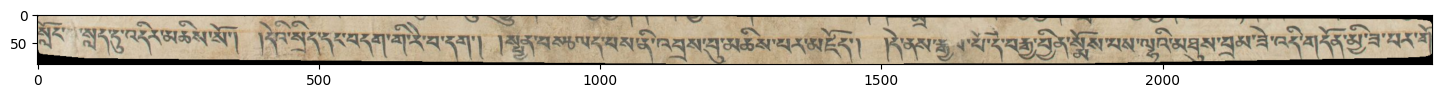

In [155]:
line_img = line_images[-1].copy()

show_image(line_img)

(80, 2000)
(2000, 80)
(1, 2000, 80)


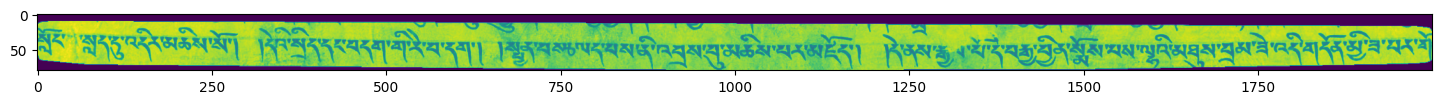

In [154]:
line_img = line_images[-1].copy()
line_img = resize_to_width(line_img, target_width=2000)
line_img = cv2.cvtColor(line_img, cv2.COLOR_RGB2GRAY)
line_img = pad_image2(line_img, target_width=2000, target_height=80, padding="black")
#line_img = tf.image.decode_jpeg(img, channels=1)
#line_img = tf.image.resize_with_pad(line_img, 80, 2000)
#line_img = line_img.numpy()
print(line_img.shape)
show_image(line_img)

line_img = np.transpose(line_img, axes=[1, 0])
print(line_img.shape)
line_img = np.expand_dims(line_img, axis=0)
line_img = tf.cast(line_img, tf.float32) / 255.0

print(line_img.shape)

(80, 2000, 1)


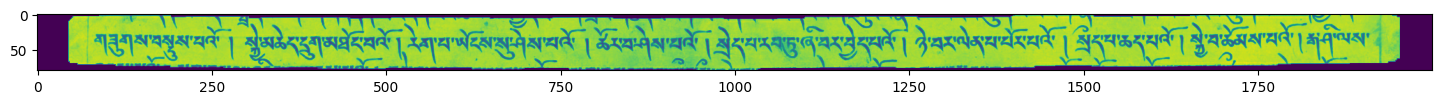

In [76]:
np_img, tf_img = read_tf_image_v1(test_img)
print(np_img.shape)
show_image(tf_img)

In [151]:
def read_tf_image(img_path: str):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=1)
    img = tf.image.resize_with_pad(img, 80, 2000)
    img = tf.cast(img, tf.float32) / 255.0
    img = tf.transpose(img, perm=[2, 1, 0])

    return img

tf_img = read_tf_image("ocr_test_line.jpg")
print(tf_img.shape)
out = predict_ocr(tf_img)
filtered_out= np.delete(out, np.where(out == -1))
filtered_list = filtered_out.tolist()
print(filtered_list)
decoded = "".join(model_chars[x] for x in filtered_list)
#decoded = decoded.replace("§", " ")
print(decoded)



(1, 2000, 80)
(1, 2000, 80)
1/1 [==============================] - 0s 472ms/step
[]



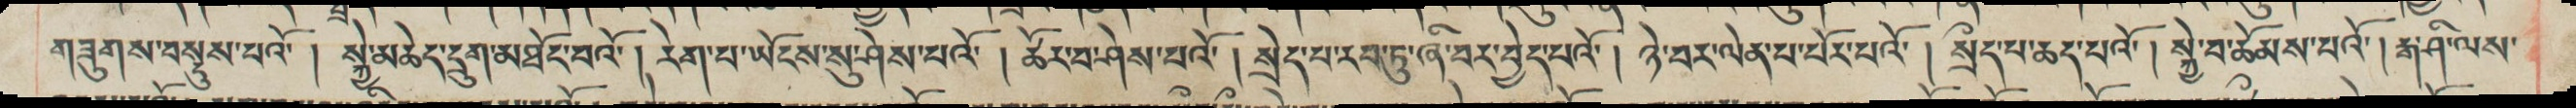

In [153]:
ShowImage(ds_lines[123])

(80, 2000, 3)


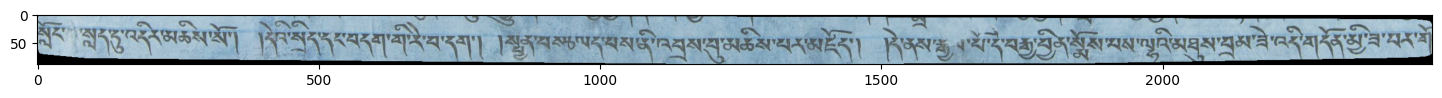

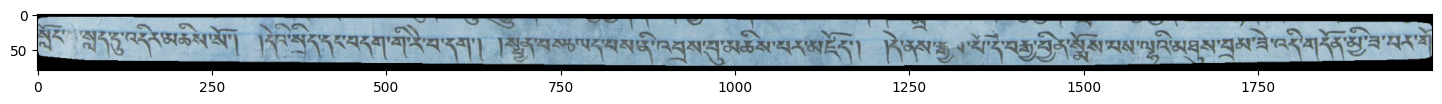

In [150]:
show_image(cv_img)

cv_img = tf.cast(cv_img, tf.float32)
cv_img = tf.image.resize_with_pad(cv_img, 80, 2000)
print(cv_img.shape)
show_image(np.array(cv_img, dtype=int))

(65, 1848, 3)


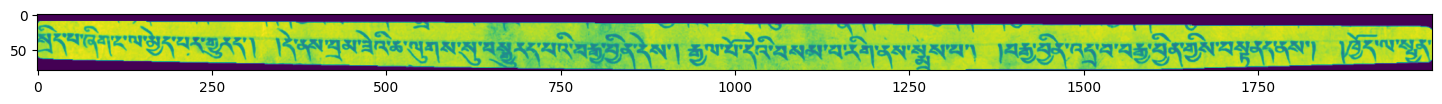

In [143]:
line_img = line_images[-2].copy()
line_img = resize_to_width(line_img, target_width=1848)
print(line_img.shape)
line_img = cv2.cvtColor(line_img, cv2.COLOR_RGB2GRAY)
line_img = pad_image2(line_img, target_width=2000, target_height=80, padding="black")

show_image(line_img)

(1, 2000, 80)


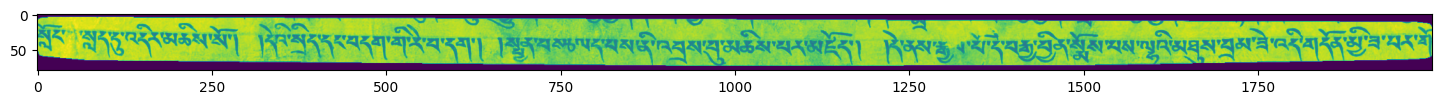

In [139]:
#cv2_img = cv2.cvtColor(cv_img, cv2.COLOR_BGR2GRAY)
cv_img = tf.image.rgb_to_grayscale(cv_img)
cv_img = cv_img / 255.0
show_image(cv_img)

cv_img = tf.transpose(cv_img, perm=[2, 1, 0])
print(cv_img.shape)

In [136]:
out = predict_ocr(cv_img)
filtered_out= np.delete(out, np.where(out == -1))
filtered_list = filtered_out.tolist()
print(filtered_list)
decoded = "".join(model_chars[x] for x in filtered_list)
#decoded = decoded.replace("§", " ")
print(decoded)

(1, 2000, 80)
1/1 [==============================] - 0s 261ms/step
[]



In [30]:
filtered_out= np.delete(out, np.where(out == -1))
filtered_list = filtered_out.tolist()
print(filtered_list)
decoded = "".join(model_chars[x] for x in filtered_list)
#decoded = decoded.replace("§", " ")
print(decoded)

[68, 11, 49, 60, 68, 44, 60, 46, 62, 60, 68, 58, 43, 4, 57, 68, 11, 60, 53, 64, 47, 68, 55, 45, 50, 47, 56, 49, 68, 46, 62, 49, 68, 55, 61, 50, 57, 56, 49, 68, 44, 43, 4, 57, 68, 11, 59, 51, 49, 68, 58, 43, 68, 64, 57, 56, 49, 60, 68, 60, 62, 68, 55, 47, 60, 68, 58, 43, 4, 57, 68, 11, 45, 50, 47, 59, 68, 58, 43, 68, 60, 50, 47, 60, 68, 58, 43, 4, 57, 68, 11, 60, 47, 46, 68, 58, 43, 68, 59, 43, 44, 68, 61, 62, 68, 54, 51, 68, 44, 43, 59, 68, 44, 64, 47, 46, 68, 58, 43, 4, 57, 68, 11, 56, 64, 47, 68, 44, 43, 59, 68, 54, 47, 56, 68, 58, 43, 68, 60, 57, 59, 68, 58, 43, 4, 57, 68, 60, 43, 46, 68, 58, 43, 68, 45, 50, 47, 46, 68, 58, 43, 4, 57, 68, 60, 53, 64, 47, 68, 44, 43, 68, 45, 60, 50, 43, 55, 60, 68, 58, 43]
&0ht&ctewt&rb`p&0tlzf&ndifoh&ewh&nuipoh&cb`p&0sjh&rb&zpoht&tw&nft&rb`p&0difs&rb&tift&rb`p&0tfe&rb&sbc&uw&mj&cbs&czfe&rb`p&0ozf&cbs&mfo&rb&tps&rb`p&tbe&rb&dife&rb`p&tlzf&cb&dtibnt&rb
